# 기능 D 굿즈 보존 배경: Y 배경 + R1n 조명 (10/30)

16 결과로 R1n(평균 밝기 유지 조명)과 Y(이어 그리기를 줄이는 배경 생성 모델)를 둘 다 UI 선택지로 두는 안이 나왔다. 결정 전에 두 방식을 합친 것을 확인한다. Y는 굿즈가 탁자에 놓인 구도로 배경을 그리지만 조명을 바꾸지 않고, R1n은 굿즈 색을 지키며 명암만 옮기지만 배경(15의 빈 배경)과 굿즈의 크기·위치가 따로 논다. 여기서는 Y 결과를 IC-Light의 배경 조건으로 넣어 조명 정보를 다시 얻고, 그 밝기 분포를 R1n 식으로 원본 굿즈에 옮긴다.

| 후보 | 방식 |
|---|---|
| Y | 16 Y 결과 그대로 (조명 변화 없음, 비교 기준) |
| IC | IC-Light FBC(15와 같은 코드·설정)에 굿즈 + Y 결과를 배경 조건으로 넣은 원출력 (굿즈 색도 바뀜, 비교용) |
| YR1n | 굿즈 = 원본 × (흐린 IC 밝기 ÷ 흐린 원본 밝기 ÷ 굿즈 안 평균 비율), 16 R1n과 같은 식 |

- 비교 조건 (YR1n 2 × 2 × 2 = 8가지)
  - `cond`: IC-Light에 넣는 배경
    - `asis`: Y 결과 그대로. Y 결과에는 굿즈가 같은 자리에 들어 있다.
    - `fill`: Y 결과에서 굿즈 자리(마스크 12px 넓힘)를 주변 배경 색으로 메운 것. 배경 조건에 같은 굿즈가 있는 것이 조명에 영향을 주는지 보기 위함이다.
  - `sigma` 8·32 (16과 같은 탐색값)
  - `base`: 굿즈를 얹을 배경
    - `y`: Y 결과
    - `ic`: IC-Light 원출력(굿즈 밖). IC-Light가 다시 그린 배경이라 그림자·반사가 들어 있을 수 있다.
- 입력: 16이 저장한 Y 입력(`outputs/background_relight/_in/`: 굿즈·마스크, 화면 틀 긴 변 1024)과 Y 결과(`Y__*.png`), 굿즈 11장 × 장면 3개
- IC-Light: 15 "D2 IC-Light 배경 조건 재조명" 셀의 `load_iclight`·`process`(데모 `gradio_demo_bg.py` 커밋 bcf3f29)를 그대로 옮겼다. 설정도 15와 같다(20스텝, CFG 7, 고해상도 1.5배·denoise 0.5, 긴 변 640, seed 0, 장면 문구 같음).
- 구멍 메우기(`fill`, 탐색값): 굿즈 밖 배경만으로 흐림(정규화 합성곱)을 1/8 크기에서 작은 흐림부터 큰 흐림 순으로 구해, 값이 있는 곳부터 채운다.
- 지표 (16과 같음, 굿즈 마스크를 4px 줄인 영역): 굿즈 구조 보존 SSIM(`prod_ssim`), 색 차이 Lab √(Δa*²+Δb*²)(`prod_dC`), 밝기 변화 |ΔL*|(`prod_dL`), 장면 문구 CLIP 유사도(`scene_sim`). 16의 Y·R1n_s32_plain·R1n_s32_ic를 함께 잰다(다시 생성하지 않음).
- 기록 (`outputs/background_y_relight/`)
  - `yr_config.json`: 설정 전문, 입력 목록, 패키지 버전, GPU
  - `yr_records.csv`: 이미지 1장마다 방식·굿즈·장면·설정·시간·최대 VRAM·오류
  - `yr_runs.csv`: 단계마다 시작·종료 시각, 모델 로드 시간, 전체 시간, 장수
  - `bg_fill/`, `ic/`(IC-Light 원출력), `yr_scored.csv`, `yr_summary.csv`, `yr_scores.png`, `yr_grid_<장면>.png`
- 진행 출력: 단계마다 `[시각 | 경과 | VRAM] 내용`을 한 줄씩 바로 출력한다(모델 로드 시작·끝, 몇 번째/전체).
- 실행 순서: 16을 끝낸 뒤, 위에서부터 차례로. 다시 실행하면 오류 없이 만든 이미지는 건너뛴다.
- 예상(추정): IC-Light 66장(33장 × cond 2) × 15 기준 장당 약 5.7초 + 로드 약 70초 ≈ 8분, YR1n 264장은 후처리라 약 1~2분. 새로 받는 모델 없음(15에서 받은 Realistic Vision v5.1·IC-Light 가중치 사용).
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정

In [1]:
import gc
import importlib.metadata
import json
import math
import platform
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageFilter

ROOT = Path('..')
REL_DIR = ROOT / 'outputs' / 'background_relight'
IN_DIR = REL_DIR / '_in'
OUT_DIR = ROOT / 'outputs' / 'background_y_relight'
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / 'bg_fill').mkdir(exist_ok=True)
(OUT_DIR / 'ic').mkdir(exist_ok=True)
REC_CSV = OUT_DIR / 'yr_records.csv'
RUNS_CSV = OUT_DIR / 'yr_runs.csv'

GOODS_DIR = ROOT / 'data' / 'raw' / 'goods'
GOODS = pd.read_csv(GOODS_DIR / 'goods_sources.csv', keep_default_na=False)
GOODS = GOODS[(GOODS.error == '') & GOODS.file.map(lambda f: (GOODS_DIR / f).exists())].reset_index(drop=True)
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
# 15·16과 같은 장면 문구
SCENES = {
    'desk': 'on a wooden desk next to a game controller and small figures, warm desk lamp light, cozy room',
    'studio': 'on a pastel color studio backdrop, soft shadow, clean background',
    'cafe': 'on a cafe table by the window, morning sunlight, shallow depth of field',
}
SEED = 0
SD15 = 'stablediffusionapi/realistic-vision-v51'
ICLIGHT = dict(repo='lllyasviel/ic-light', file='iclight_sd15_fbc.safetensors', code_commit='bcf3f29ca85be8a4686215f477b546f5030be8b7')
# IC-Light 데모(gradio_demo_bg.py) 기본값, 15와 같음
D2_ARGS = dict(steps=20, cfg=7.0, highres_scale=1.5, highres_denoise=0.5, max_side=640, a_prompt='best quality',
               n_prompt='lowres, bad anatomy, bad hands, cropped, worst quality')
CONDS = ['asis', 'fill']
FILL_DILATE_PX = 12
SIGMAS = [8, 32]
BASES = ['y', 'ic']
RATIO_CLIP = (0.25, 4.0)
VARIANTS = [dict(method=f'YR1n_s{s}_{c}_{b}', cond=c, sigma=s, base=b) for c in CONDS for s in SIGMAS for b in BASES]


def scene_prompt(kind, scene):
    return f'product photography of a {KIND_EN[kind]} {SCENES[scene]}'


def out_name(method, name, scene):
    return f'{method}__{Path(name).stem}__{scene}.png'


def inputs(name, scene):
    # 16 Y 입력과 같은 틀(긴 변 1024)의 원본 굿즈·마스크, Y 결과
    st = f'{Path(name).stem}__{scene}'
    goods = np.asarray(Image.open(IN_DIR / f'{st}.png').convert('RGB'), dtype=np.float32) / 255
    alpha = np.asarray(Image.open(IN_DIR / f'{st}_mask.png').convert('L'), dtype=np.float32) / 255
    ybg = np.asarray(Image.open(REL_DIR / out_name('Y', name, scene)).convert('RGB'), dtype=np.float32) / 255
    return goods, alpha, ybg


need = [p for g in GOODS.file for sc in SCENES for p in
        [IN_DIR / f'{Path(g).stem}__{sc}.png', IN_DIR / f'{Path(g).stem}__{sc}_mask.png', REL_DIR / out_name('Y', g, sc)]]
miss = [str(p) for p in need if not p.exists()]
assert not miss, f'16 Y 결과가 없음 → 16을 먼저 끝까지 실행: {miss[:3]}'
print('굿즈', len(GOODS), '장 × 장면', len(SCENES), '| IC-Light', len(GOODS) * len(SCENES) * len(CONDS), '장 | YR1n', len(VARIANTS), '가지')

recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f, sub=''):
    return recs.get(f, {}).get('error', 'x') == '' and (OUT_DIR / sub / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


def append_csv(path, rec):
    pd.DataFrame([rec]).to_csv(path, mode='a', header=not path.exists(), index=False, encoding='utf-8-sig')


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 멈춤 여부를 바로 알 수 있게 단계마다 시각·단계 시작 후 경과·VRAM(현재/최대)을 함께 출력
def log(msg, t_start=None):
    el = ''
    if t_start is not None:
        m, sec = divmod(int(time.perf_counter() - t_start), 60)
        el = f' | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d}'
    vr = ''
    if torch.cuda.is_available():
        vr = f' | VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")}{el}{vr}] {msg}', flush=True)


def blur(x, sigma, pad='reflect'):
    # 분리형 가우시안 (x: H×W×C float)
    r = int(3 * sigma)
    k = torch.exp(-(torch.arange(-r, r + 1, dtype=torch.float32) ** 2) / (2 * sigma ** 2))
    k = k / k.sum()
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    t = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))[:, None].to(dev)
    k = k.to(dev)
    t = F.conv2d(F.pad(t, (r, r, 0, 0), mode=pad), k.view(1, 1, 1, -1))
    t = F.conv2d(F.pad(t, (0, 0, r, r), mode=pad), k.view(1, 1, -1, 1))
    return t[:, 0].cpu().numpy().transpose(1, 2, 0)


def masked_blur(x, a, sigma):
    # 굿즈 안쪽 값만으로 흐림 (정규화 합성곱), 16과 같음
    return blur(x * a[..., None], sigma) / np.maximum(blur(a[..., None], sigma), 1e-4)


def luma(x):
    return (x @ np.array([0.299, 0.587, 0.114], dtype=np.float32))[..., None]


def relight_n(goods, alpha, ic, sigma):
    # 16 R1n과 같은 식: 밝기 비율을 굿즈 안(알파 가중) 평균으로 나눠 전체 밝기는 원본 유지
    ratio = (masked_blur(luma(ic), alpha, sigma) + 1e-3) / (masked_blur(luma(goods), alpha, sigma) + 1e-3)
    mean = float((ratio[..., 0] * alpha).sum() / max(alpha.sum(), 1e-6))
    return (goods * np.clip(ratio / mean, *RATIO_CLIP)).clip(0, 1)

굿즈 11 장 × 장면 3 | IC-Light 66 장 | YR1n 8 가지


## Y 배경의 굿즈 자리 메우기 (`fill`)

In [2]:
def fill_hole(img, alpha):
    # 굿즈 자리(마스크 넓힘)를 주변 배경으로 메움: 1/8 크기에서 작은 흐림부터 큰 흐림 순으로 값이 있는 곳을 채움
    hole = np.asarray(Image.fromarray(((alpha > 0.5) * 255).astype(np.uint8)).filter(
        ImageFilter.MaxFilter(2 * FILL_DILATE_PX + 1)), dtype=np.float32) / 255
    h, w = hole.shape
    sw, sh = max(w // 8, 8), max(h // 8, 8)
    small = np.asarray(Image.fromarray((img * 255).astype(np.uint8)).resize((sw, sh), Image.BOX), dtype=np.float32) / 255
    keep = 1 - np.asarray(Image.fromarray((hole * 255).astype(np.uint8)).resize((sw, sh), Image.BOX), dtype=np.float32) / 255
    keep = (keep > 0.99).astype(np.float32)
    est, have = small * keep[..., None], keep.copy()
    for s in [1, 2, 4, 8, 16, 32]:
        den = blur(keep[..., None], s, pad='replicate')[..., 0]
        e = blur(small * keep[..., None], s, pad='replicate') / np.maximum(den, 1e-6)[..., None]
        new = (have == 0) & (den > 0.02)
        est[new], have[new] = e[new], 1
    # 채운 순서에 따라 생기는 계단 무늬를 줄이려고 메운 부분만 한 번 더 흐림
    est = np.where(keep[..., None] > 0, est, blur(est, 3, pad='replicate'))
    big = np.asarray(Image.fromarray((est.clip(0, 1) * 255).round().astype(np.uint8)).resize((w, h), Image.BICUBIC),
                     dtype=np.float32) / 255
    a = np.asarray(Image.fromarray((hole * 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(4)), dtype=np.float32)[..., None] / 255
    return img * (1 - a) + big * a


todo_f = [(g, sc) for g in GOODS.itertuples() for sc in SCENES if not (OUT_DIR / 'bg_fill' / f'{Path(g.file).stem}__{sc}.png').exists()]
t_all = time.perf_counter()
log(f'메우기 {len(todo_f)}장', t_all)
for i, (g, sc) in enumerate(todo_f, 1):
    goods, alpha, ybg = inputs(g.file, sc)
    Image.fromarray((fill_hole(ybg, alpha) * 255).round().clip(0, 255).astype(np.uint8)).save(
        OUT_DIR / 'bg_fill' / f'{Path(g.file).stem}__{sc}.png')
    if i % 11 == 0 or i == len(todo_f):
        log(f'메우기 {i}/{len(todo_f)}', t_all)

[11:37:49 | 경과 0:00:00 | VRAM 0.0GB (최대 0.0GB)] 메우기 33장
[11:37:56 | 경과 0:00:07 | VRAM 0.0GB (최대 0.0GB)] 메우기 11/33
[11:38:03 | 경과 0:00:13 | VRAM 0.0GB (최대 0.0GB)] 메우기 22/33
[11:38:09 | 경과 0:00:20 | VRAM 0.0GB (최대 0.0GB)] 메우기 33/33


## IC-Light (Y 배경 조건)

In [3]:
# 15 "D2 IC-Light 배경 조건 재조명" 셀과 같은 코드 (IC-Light 공식 데모 gradio_demo_bg.py 커밋 bcf3f29). 바꾼 점: 배경 제거 대신 BiRefNet 마스크
import safetensors.torch as sf
from diffusers import AutoencoderKL, DPMSolverMultistepScheduler, StableDiffusionImg2ImgPipeline, StableDiffusionPipeline, UNet2DConditionModel
from diffusers.models.attention_processor import AttnProcessor2_0
from huggingface_hub import hf_hub_download
from transformers import CLIPTextModel, CLIPTokenizer


def load_iclight():
    tokenizer = CLIPTokenizer.from_pretrained(SD15, subfolder='tokenizer')
    text_encoder = CLIPTextModel.from_pretrained(SD15, subfolder='text_encoder')
    vae = AutoencoderKL.from_pretrained(SD15, subfolder='vae')
    unet = UNet2DConditionModel.from_pretrained(SD15, subfolder='unet')
    with torch.no_grad():
        new_conv_in = torch.nn.Conv2d(12, unet.conv_in.out_channels, unet.conv_in.kernel_size, unet.conv_in.stride, unet.conv_in.padding)
        new_conv_in.weight.zero_()
        new_conv_in.weight[:, :4, :, :].copy_(unet.conv_in.weight)
        new_conv_in.bias = unet.conv_in.bias
        unet.conv_in = new_conv_in
    unet_original_forward = unet.forward

    def hooked_unet_forward(sample, timestep, encoder_hidden_states, **kwargs):
        c_concat = kwargs['cross_attention_kwargs']['concat_conds'].to(sample)
        c_concat = torch.cat([c_concat] * (sample.shape[0] // c_concat.shape[0]), dim=0)
        new_sample = torch.cat([sample, c_concat], dim=1)
        kwargs['cross_attention_kwargs'] = {}
        return unet_original_forward(new_sample, timestep, encoder_hidden_states, **kwargs)

    unet.forward = hooked_unet_forward
    sd_offset = sf.load_file(hf_hub_download(ICLIGHT['repo'], ICLIGHT['file']))
    sd_origin = unet.state_dict()
    unet.load_state_dict({k: sd_origin[k] + sd_offset[k] for k in sd_origin.keys()}, strict=True)
    del sd_offset, sd_origin
    text_encoder = text_encoder.to(device='cuda', dtype=torch.float16)
    vae = vae.to(device='cuda', dtype=torch.bfloat16)
    unet = unet.to(device='cuda', dtype=torch.float16)
    unet.set_attn_processor(AttnProcessor2_0())
    vae.set_attn_processor(AttnProcessor2_0())
    sched = DPMSolverMultistepScheduler(num_train_timesteps=1000, beta_start=0.00085, beta_end=0.012,
                                        algorithm_type='sde-dpmsolver++', use_karras_sigmas=True, steps_offset=1)
    kw = dict(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet, scheduler=sched, safety_checker=None,
              requires_safety_checker=False, feature_extractor=None, image_encoder=None)
    return tokenizer, text_encoder, vae, StableDiffusionPipeline(**kw), StableDiffusionImg2ImgPipeline(**kw)


@torch.inference_mode()
def encode_prompt_inner(txt):
    max_length = tokenizer.model_max_length
    chunk_length = tokenizer.model_max_length - 2
    id_start, id_end = tokenizer.bos_token_id, tokenizer.eos_token_id

    def pad(x, p, i):
        return x[:i] if len(x) >= i else x + [p] * (i - len(x))

    tokens = tokenizer(txt, truncation=False, add_special_tokens=False)['input_ids']
    chunks = [[id_start] + tokens[i: i + chunk_length] + [id_end] for i in range(0, len(tokens), chunk_length)]
    chunks = [pad(ck, id_end, max_length) for ck in chunks]
    return text_encoder(torch.tensor(chunks).to(device='cuda', dtype=torch.int64)).last_hidden_state


@torch.inference_mode()
def encode_prompt_pair(positive_prompt, negative_prompt):
    c, uc = encode_prompt_inner(positive_prompt), encode_prompt_inner(negative_prompt)
    max_count = max(float(len(c)), float(len(uc)))
    max_chunk = max(len(c), len(uc))
    c = torch.cat([c] * int(math.ceil(max_count / len(c))), dim=0)[:max_chunk]
    uc = torch.cat([uc] * int(math.ceil(max_count / len(uc))), dim=0)[:max_chunk]
    return torch.cat([p[None, ...] for p in c], dim=1), torch.cat([p[None, ...] for p in uc], dim=1)


@torch.inference_mode()
def pytorch2numpy(imgs, quant=True):
    out = []
    for x in imgs:
        y = x.movedim(0, -1)
        if quant:
            out.append((y * 127.5 + 127.5).detach().float().cpu().numpy().clip(0, 255).astype(np.uint8))
        else:
            out.append((y * 0.5 + 0.5).detach().float().cpu().numpy().clip(0, 1).astype(np.float32))
    return out


@torch.inference_mode()
def numpy2pytorch(imgs):
    return (torch.from_numpy(np.stack(imgs, axis=0)).float() / 127.0 - 1.0).movedim(-1, 1)


def resize_and_center_crop(image, tw, th):
    pil = Image.fromarray(image)
    s = max(tw / pil.width, th / pil.height)
    rw, rh = int(round(pil.width * s)), int(round(pil.height * s))
    pil = pil.resize((rw, rh), Image.LANCZOS)
    return np.array(pil.crop(((rw - tw) / 2, (rh - th) / 2, (rw + tw) / 2, (rh + th) / 2)))


def resize_without_crop(image, tw, th):
    return np.array(Image.fromarray(image).resize((tw, th), Image.LANCZOS))


@torch.inference_mode()
def process(input_fg, input_bg, prompt, w, h, seed, steps, a_prompt, n_prompt, cfg, highres_scale, highres_denoise):
    rng = torch.Generator(device='cuda').manual_seed(seed)
    fg, bg = resize_and_center_crop(input_fg, w, h), resize_and_center_crop(input_bg, w, h)
    cc = vae.encode(numpy2pytorch([fg, bg]).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    cc = torch.cat([c[None, ...] for c in cc], dim=1)
    conds, unconds = encode_prompt_pair(prompt + ', ' + a_prompt, n_prompt)
    latents = t2i_pipe(prompt_embeds=conds, negative_prompt_embeds=unconds, width=w, height=h, num_inference_steps=steps,
                       num_images_per_prompt=1, generator=rng, output_type='latent', guidance_scale=cfg,
                       cross_attention_kwargs={'concat_conds': cc}).images.to(vae.dtype) / vae.config.scaling_factor
    pixels = pytorch2numpy(vae.decode(latents).sample)
    pixels = [resize_without_crop(p, int(round(w * highres_scale / 64.0) * 64), int(round(h * highres_scale / 64.0) * 64)) for p in pixels]
    latents = vae.encode(numpy2pytorch(pixels).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    latents = latents.to(device=t2i_pipe.unet.device, dtype=t2i_pipe.unet.dtype)
    h2, w2 = latents.shape[2] * 8, latents.shape[3] * 8
    fg, bg = resize_and_center_crop(input_fg, w2, h2), resize_and_center_crop(input_bg, w2, h2)
    cc = vae.encode(numpy2pytorch([fg, bg]).to(device=vae.device, dtype=vae.dtype)).latent_dist.mode() * vae.config.scaling_factor
    cc = torch.cat([c[None, ...] for c in cc], dim=1)
    latents = i2i_pipe(image=latents, strength=highres_denoise, prompt_embeds=conds, negative_prompt_embeds=unconds, width=w2,
                       height=h2, num_inference_steps=int(round(steps / highres_denoise)), num_images_per_prompt=1, generator=rng,
                       output_type='latent', guidance_scale=cfg,
                       cross_attention_kwargs={'concat_conds': cc}).images.to(vae.dtype) / vae.config.scaling_factor
    return pytorch2numpy(vae.decode(latents).sample, quant=False)[0]



todo_ic = [(g, sc, c) for g in GOODS.itertuples() for sc in SCENES for c in CONDS if not done(out_name(f'IC_{c}', g.file, sc), 'ic')]
print('IC-Light', len(todo_ic), '장')
if todo_ic:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    log('IC-Light 로드 시작', t_all)
    tokenizer, text_encoder, vae, t2i_pipe, i2i_pipe = load_iclight()
    load_sec = round(time.perf_counter() - t_all, 1)
    log(f'IC-Light 로드 끝 {load_sec}초', t_all)
    peak = 0.0
    for i, (g, sc, c) in enumerate(todo_ic, 1):
        f = out_name(f'IC_{c}', g.file, sc)
        goods, alpha, ybg = inputs(g.file, sc)
        bg = ybg if c == 'asis' else np.asarray(Image.open(OUT_DIR / 'bg_fill' / f'{Path(g.file).stem}__{sc}.png').convert('RGB'),
                                                 dtype=np.float32) / 255
        h0, w0 = alpha.shape
        s = D2_ARGS['max_side'] / max(w0, h0)
        w, h = int(round(w0 * s / 64)) * 64, int(round(h0 * s / 64)) * 64
        # 데모 run_rmbg와 같은 회색(127) 배경 전경 (15와 같음)
        fg = (127 + (goods * 255 - 127) * alpha[..., None]).clip(0, 255).astype(np.uint8)
        rec = dict(file=f, method=f'IC_{c}', goods=g.file, kind=g.kind, scene=sc, params=json.dumps(
            dict(D2_ARGS, cond=c, prompt=scene_prompt(g.kind, sc), width=w, height=h, sd15=SD15, iclight=ICLIGHT)), error='')
        try:
            torch.cuda.reset_peak_memory_stats()
            t0 = time.perf_counter()
            res = process(fg, (bg * 255).round().astype(np.uint8), scene_prompt(g.kind, sc), w, h, SEED, D2_ARGS['steps'],
                          D2_ARGS['a_prompt'], D2_ARGS['n_prompt'], D2_ARGS['cfg'], D2_ARGS['highres_scale'], D2_ARGS['highres_denoise'])
            Image.fromarray((res * 255).clip(0, 255).astype(np.uint8)).save(OUT_DIR / 'ic' / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            peak = max(peak, rec['peak_vram_gb'])
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
        log(f'IC-Light {i}/{len(todo_ic)} {f} {rec.get("sec")}초 {rec["error"][:100]}', t_all)
    append_csv(RUNS_CSV, dict(stage='IC-Light (Y 배경 조건)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=len(todo_ic), load_sec=load_sec, peak_vram_gb=peak))
    del t2i_pipe, i2i_pipe, text_encoder, vae
    gc.collect()
    torch.cuda.empty_cache()

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1030 11:38:20.697000 38600 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 11:38:20.781000 38600 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading 

IC-Light 66 장
[11:38:32 | 경과 0:00:00 | VRAM 0.0GB (최대 0.0GB)] IC-Light 로드 시작


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 2298.80it/s]
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


[11:38:40 | 경과 0:00:08 | VRAM 2.0GB (최대 2.0GB)] IC-Light 로드 끝 8.1초


100%|██████████| 20/20 [00:04<00:00,  4.49it/s]


[11:38:48 | 경과 0:00:16 | VRAM 2.0GB (최대 4.5GB)] IC-Light 1/66 IC_asis__mug_01__desk.png 8.23초 


... (126 outputs left out)

100%|██████████| 20/20 [00:02<00:00,  7.66it/s]


[11:44:35 | 경과 0:06:03 | VRAM 2.0GB (최대 3.6GB)] IC-Light 65/66 IC_asis__hoodie_02__cafe.png 4.56초 


100%|██████████| 20/20 [00:02<00:00,  7.63it/s]


[11:44:40 | 경과 0:06:08 | VRAM 2.0GB (최대 3.6GB)] IC-Light 66/66 IC_fill__hoodie_02__cafe.png 4.57초 


## YR1n 조명 옮기기 (후처리)

In [4]:
todo_r = [(g, sc, v) for g in GOODS.itertuples() for sc in SCENES for v in VARIANTS if not done(out_name(v['method'], g.file, sc))]
print('YR1n', len(todo_r), '/', len(GOODS) * len(SCENES) * len(VARIANTS), '장')
if todo_r:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    for i, (g, sc, v) in enumerate(todo_r, 1):
        f = out_name(v['method'], g.file, sc)
        rec = dict(file=f, method=v['method'], goods=g.file, kind=g.kind, scene=sc,
                   params=json.dumps(dict(v, ratio_clip=RATIO_CLIP, norm=True)), error='')
        try:
            t0 = time.perf_counter()
            goods, alpha, ybg = inputs(g.file, sc)
            ic = np.asarray(Image.open(OUT_DIR / 'ic' / out_name(f'IC_{v["cond"]}', g.file, sc)).convert('RGB').resize(
                (alpha.shape[1], alpha.shape[0]), Image.LANCZOS), dtype=np.float32) / 255
            fg = relight_n(goods, alpha, ic, v['sigma'])
            base = ybg if v['base'] == 'y' else ic
            a = alpha[..., None]
            Image.fromarray(((fg * a + base * (1 - a)) * 255).round().clip(0, 255).astype(np.uint8)).save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
        if i % len(VARIANTS) == 0 or rec['error'] or i == len(todo_r):
            log(f'YR1n {i}/{len(todo_r)} {f} {rec.get("sec")}초 {rec["error"][:100]}', t_all)
    append_csv(RUNS_CSV, dict(stage='YR1n (후처리)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=len(todo_r), load_sec=0, peak_vram_gb=0))

config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), goods=GOODS[['file', 'kind', 'site', 'page']].to_dict('records'), scenes=SCENES,
    seed=SEED, inputs_from=str(REL_DIR), iclight=dict(sd15=SD15, **ICLIGHT, **D2_ARGS), conds=CONDS, fill_dilate_px=FILL_DILATE_PX,
    variants=VARIANTS, ratio_clip=RATIO_CLIP,
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'accelerate', 'safetensors', 'pillow', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'yr_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
rr = pd.read_csv(REC_CSV, keep_default_na=False)
print('기록', len(rr), '장 | 오류', (rr.error != '').sum())
display(rr[rr.error != ''][['file', 'error']].head(10))

YR1n 264 / 264 장
[11:44:42 | 경과 0:00:02 | VRAM 0.0GB (최대 3.6GB)] YR1n 8/264 YR1n_s32_fill_ic__mug_01__desk.png 0.27초 
[11:44:44 | 경과 0:00:04 | VRAM 0.0GB (최대 3.6GB)] YR1n 16/264 YR1n_s32_fill_ic__mug_01__studio.png 0.28초 
[11:44:47 | 경과 0:00:06 | VRAM 0.0GB (최대 3.6GB)] YR1n 24/264 YR1n_s32_fill_ic__mug_01__cafe.png 0.29초 
[11:44:48 | 경과 0:00:08 | VRAM 0.0GB (최대 3.6GB)] YR1n 32/264 YR1n_s32_fill_ic__mug_02__desk.png 0.2초 
[11:44:50 | 경과 0:00:09 | VRAM 0.0GB (최대 3.6GB)] YR1n 40/264 YR1n_s32_fill_ic__mug_02__studio.png 0.2초 
[11:44:52 | 경과 0:00:11 | VRAM 0.0GB (최대 3.6GB)] YR1n 48/264 YR1n_s32_fill_ic__mug_02__cafe.png 0.19초 
[11:44:53 | 경과 0:00:13 | VRAM 0.0GB (최대 3.6GB)] YR1n 56/264 YR1n_s32_fill_ic__mug_03__desk.png 0.19초 
[11:44:55 | 경과 0:00:14 | VRAM 0.0GB (최대 3.6GB)] YR1n 64/264 YR1n_s32_fill_ic__mug_03__studio.png 0.18초 
[11:44:56 | 경과 0:00:16 | VRAM 0.0GB (최대 3.6GB)] YR1n 72/264 YR1n_s32_fill_ic__mug_03__cafe.png 0.19초 
[11:44:58 | 경과 0:00:17 | VRAM 0.0GB (최대 3.6GB)] YR1n 80/264 YR

,file,error


## 지표

In [5]:
def _box(x, r=3):
    # 7×7 평균 필터 (누적합), 15·16과 같음
    p = np.pad(x, r + 1, mode='edge')
    c = p.cumsum(0).cumsum(1)
    k = 2 * r + 1
    return (c[k:, k:] - c[:-k, k:] - c[k:, :-k] + c[:-k, :-k])[:x.shape[0], :x.shape[1]] / (k * k)


def ssim_map(a, b):
    # 회색조 SSIM (Wang et al. 2004 상수, 7×7 평균 창), 입력 0~1
    # 누적합 정밀도 때문에 float64 (float32면 1024px에서 값이 무너짐)
    a, b = luma(a)[..., 0].astype(np.float64) * 255, luma(b)[..., 0].astype(np.float64) * 255
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    ma, mb = _box(a), _box(b)
    va, vb, cov = _box(a * a) - ma ** 2, _box(b * b) - mb ** 2, _box(a * b) - ma * mb
    return ((2 * ma * mb + c1) * (2 * cov + c2)) / ((ma ** 2 + mb ** 2 + c1) * (va + vb + c2))


def to_lab(x):
    # sRGB(D65) → CIE Lab
    c = np.where(x > 0.04045, ((x + 0.055) / 1.055) ** 2.4, x / 12.92)
    m = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    xyz = c @ m.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], -1)


from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def unit(e):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    e = (e.pooler_output if hasattr(e, 'pooler_output') else e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


with torch.no_grad():
    SCENE_E = dict(zip(SCENES, unit(clip.get_text_features(**clip_proc(text=list(SCENES.values()), return_tensors='pt',
                                                                         padding=True, truncation=True).to('cuda')))))

# 16의 Y·R1n도 함께 잼 (다시 생성하지 않음)
REF = ['Y', 'R1n_s32_plain', 'R1n_s32_ic']
rows_in = [dict(path=REL_DIR / out_name(m, g.file, sc), method=m, goods=g.file, kind=g.kind, scene=sc)
           for g in GOODS.itertuples() for sc in SCENES for m in REF]
rr = pd.read_csv(REC_CSV, keep_default_na=False)
rr = rr[rr.error == '']
rows_in += [dict(path=OUT_DIR / ('ic' if r.method.startswith('IC_') else '') / r.file, method=r.method, goods=r.goods, kind=r.kind,
                 scene=r.scene) for r in rr.itertuples()]
rows, t_all = [], time.perf_counter()
log(f'지표 시작 {len(rows_in)}장', t_all)
for i, r in enumerate(rows_in, 1):
    goods, alpha, _ = inputs(r['goods'], r['scene'])
    im = Image.open(r['path']).convert('RGB').resize((alpha.shape[1], alpha.shape[0]), Image.LANCZOS)
    out = np.asarray(im, dtype=np.float32) / 255
    prod = np.asarray(Image.fromarray((alpha > 0.5).astype(np.uint8) * 255).filter(ImageFilter.MinFilter(9))) > 0
    lo, lr = to_lab(goods)[prod], to_lab(out)[prod]
    with torch.no_grad():
        e = unit(clip.get_image_features(**clip_proc(images=[im], return_tensors='pt').to('cuda')))[0]
    rows.append(dict(file=r['path'].name, method=r['method'], goods=r['goods'], kind=r['kind'], scene=r['scene'],
                     prod_ssim=float(ssim_map(goods, out)[prod].mean()), prod_dC=float(np.linalg.norm(lr[:, 1:] - lo[:, 1:], axis=1).mean()),
                     prod_dL=float(np.abs(lr[:, 0] - lo[:, 0]).mean()), scene_sim=float(e @ SCENE_E[r['scene']])))
    if i % 66 == 0 or i == len(rows_in):
        log(f'지표 {i}/{len(rows_in)}', t_all)
ds = pd.DataFrame(rows)
ds.to_csv(OUT_DIR / 'yr_scored.csv', index=False, encoding='utf-8-sig')
ORDER = [m for m in REF + ['IC_asis', 'IC_fill'] + [v['method'] for v in VARIANTS] if m in set(ds.method)]
summ = ds.groupby('method')[['prod_ssim', 'prod_dC', 'prod_dL', 'scene_sim']].agg(['mean', 'std']).reindex(ORDER)
summ.to_csv(OUT_DIR / 'yr_summary.csv', encoding='utf-8-sig')
display(summ.round(3))
print('종류별 굿즈 밝기 변화(prod_dL)')
display(ds.pivot_table(index='method', columns='kind', values='prod_dL').reindex(ORDER).round(2))
del clip
gc.collect()
torch.cuda.empty_cache()

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 20966.25it/s]


[11:45:36 | 경과 0:00:00 | VRAM 0.6GB (최대 3.6GB)] 지표 시작 429장
[11:46:19 | 경과 0:00:42 | VRAM 0.6GB (최대 3.6GB)] 지표 66/429
[11:47:01 | 경과 0:01:24 | VRAM 0.6GB (최대 3.6GB)] 지표 132/429
[11:47:48 | 경과 0:02:11 | VRAM 0.6GB (최대 3.6GB)] 지표 198/429
[11:48:28 | 경과 0:02:51 | VRAM 0.6GB (최대 3.6GB)] 지표 264/429
[11:49:09 | 경과 0:03:32 | VRAM 0.6GB (최대 3.6GB)] 지표 330/429
[11:49:50 | 경과 0:04:13 | VRAM 0.6GB (최대 3.6GB)] 지표 396/429
[11:50:11 | 경과 0:04:34 | VRAM 0.6GB (최대 3.6GB)] 지표 429/429


prod_ssim        prod_dC         prod_dL        scene_sim  \
                      mean    std    mean     std    mean    std      mean   
method                                                                       
Y                    1.000  0.000   0.000   0.000   0.000  0.000     0.247   
R1n_s32_plain        0.993  0.009   0.300   0.209   3.338  2.373     0.264   
R1n_s32_ic           0.993  0.009   0.322   0.196   3.336  2.378     0.261   
IC_asis              0.853  0.071  20.246  10.533   9.046  5.253     0.255   
IC_fill              0.843  0.076  25.771  10.877  10.489  6.307     0.253   
YR1n_s8_asis_y       0.975  0.027   0.370   0.393   4.293  3.562     0.249   
YR1n_s8_asis_ic      0.975  0.027   0.384   0.384   4.310  3.574     0.248   
YR1n_s32_asis_y      0.993  0.014   0.272   0.322   3.319  3.225     0.248   
YR1n_s32_asis_ic     0.993  0.014   0.291   0.312   3.333  3.237     0.246   
YR1n_s8_fill_y       0.967  0.031   0.448   0.375   5.568  4.708     0.249   
YR1n_s8_fill_ic      0.967  0.031   0.475   0.367   5.584  4.723     0.249   
YR1n_s32_fill_y      0.988  0.021   0.334   0.303   4.535  4.422     0.249   
YR1n_s32_fill_ic     0.988  0.022   0.368   0.288   4.550  4.438     0.248   

                         
                    std  
method                   
Y                 0.032  
R1n_s32_plain     0.030  
R1n_s32_ic        0.031  
IC_asis           0.032  
IC_fill           0.031  
YR1n_s8_asis_y    0.033  
YR1n_s8_asis_ic   0.031  
YR1n_s32_asis_y   0.033  
YR1n_s32_asis_ic  0.031  
YR1n_s8_fill_y    0.032  
YR1n_s8_fill_ic   0.032  
YR1n_s32_fill_y   0.032  
YR1n_s32_fill_ic  0.033

종류별 굿즈 밝기 변화(prod_dL)


kind,hoodie,mug,tote,tshirt
method,,,,
Y,0.00,0.00,0.00,0.00
R1n_s32_plain,1.99,4.65,3.05,2.49
R1n_s32_ic,1.98,4.66,3.05,2.48
IC_asis,5.51,11.75,9.98,5.76
IC_fill,13.03,13.61,5.70,8.89
YR1n_s8_asis_y,3.34,6.83,3.26,1.73
YR1n_s8_asis_ic,3.36,6.85,3.28,1.73
YR1n_s32_asis_y,2.01,5.76,2.27,1.31
YR1n_s32_asis_ic,2.02,5.78,2.29,1.32


## 시각화

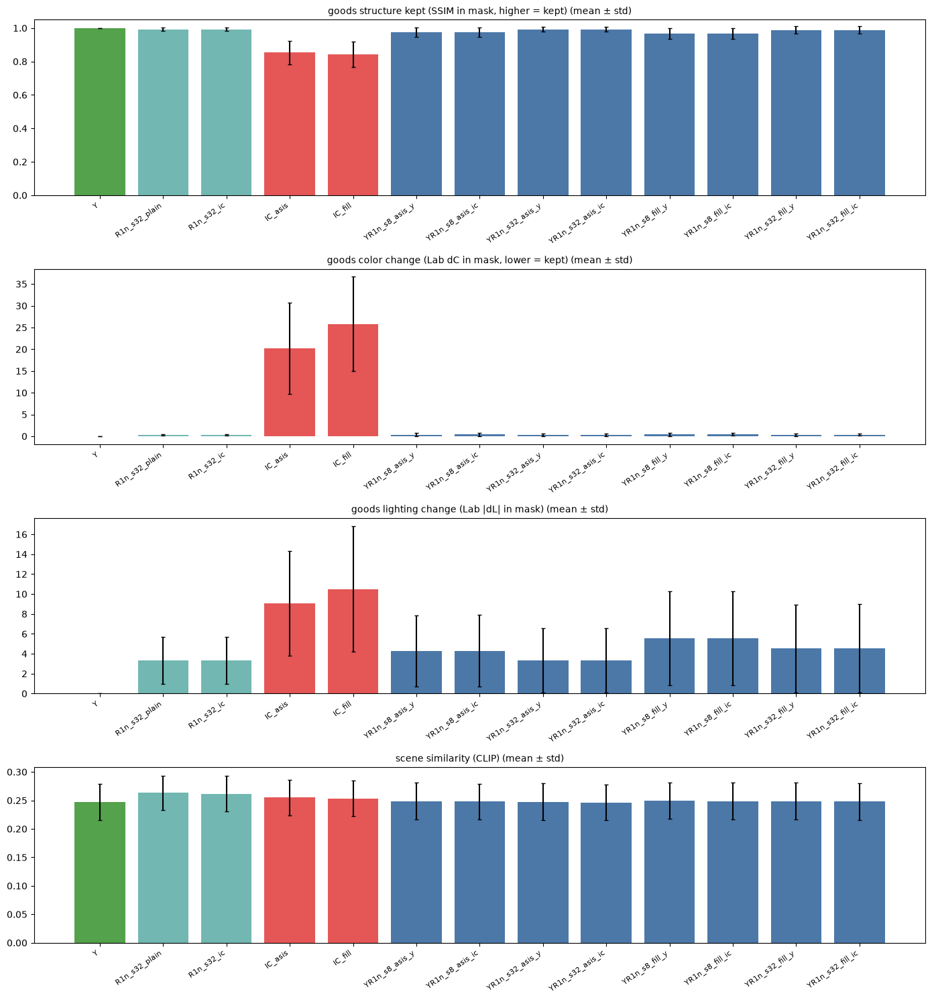

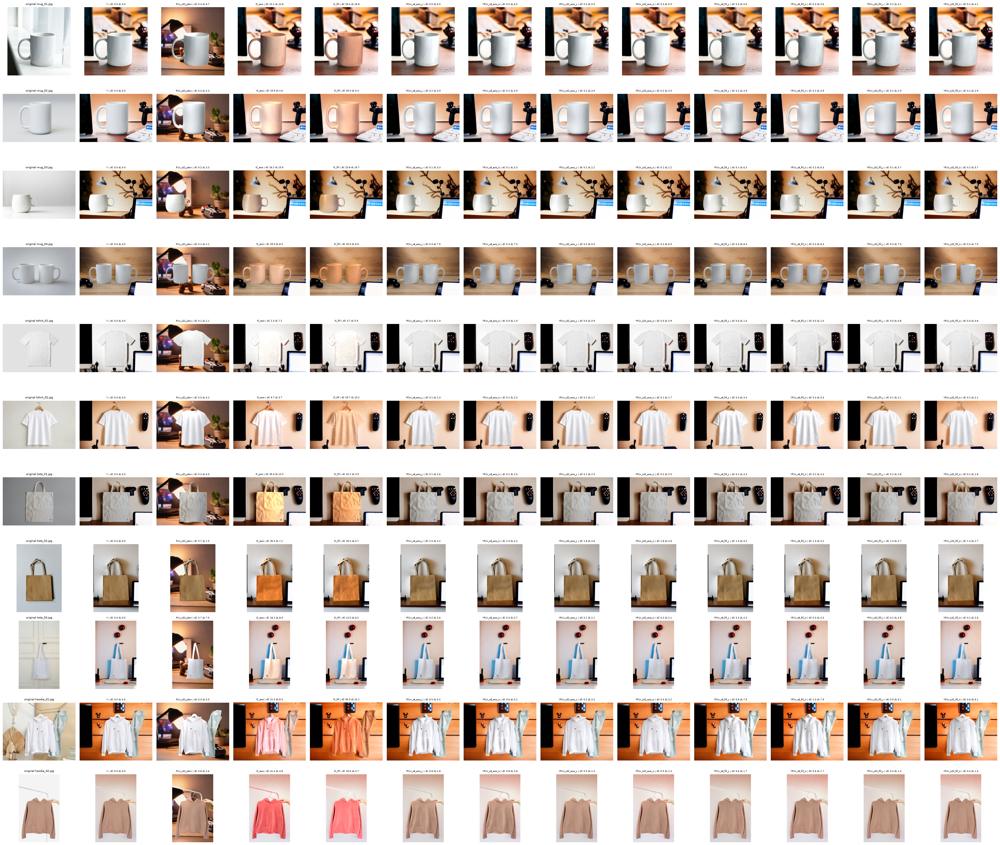

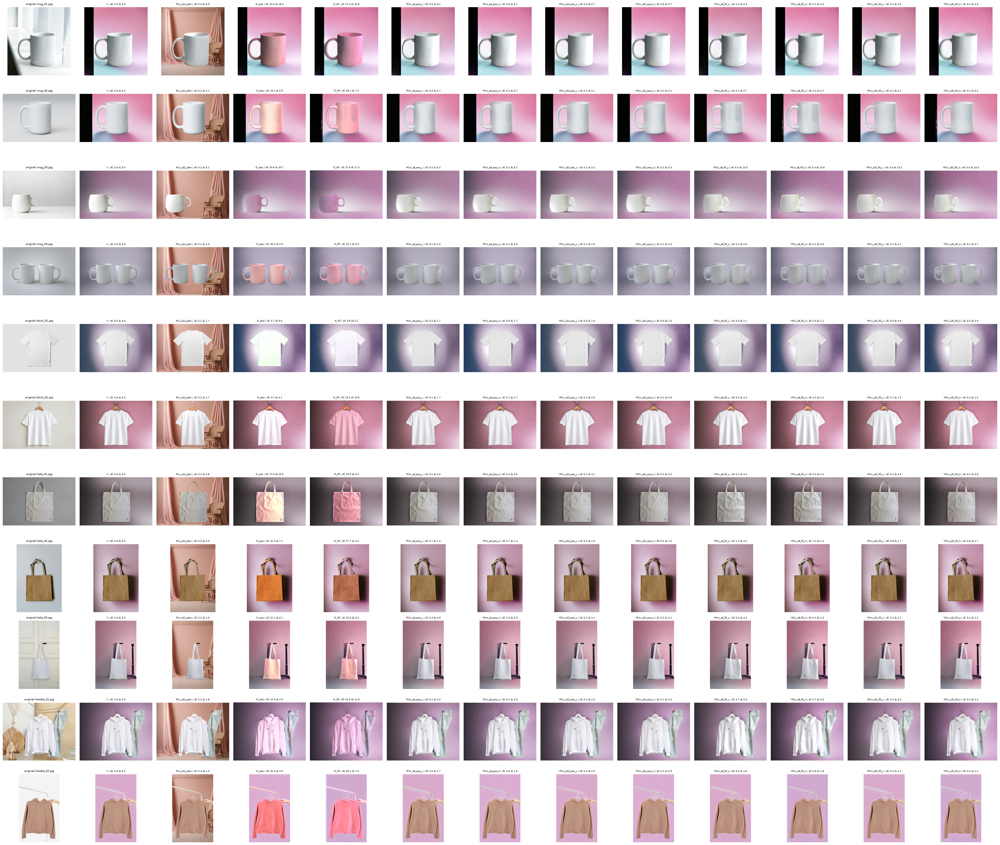

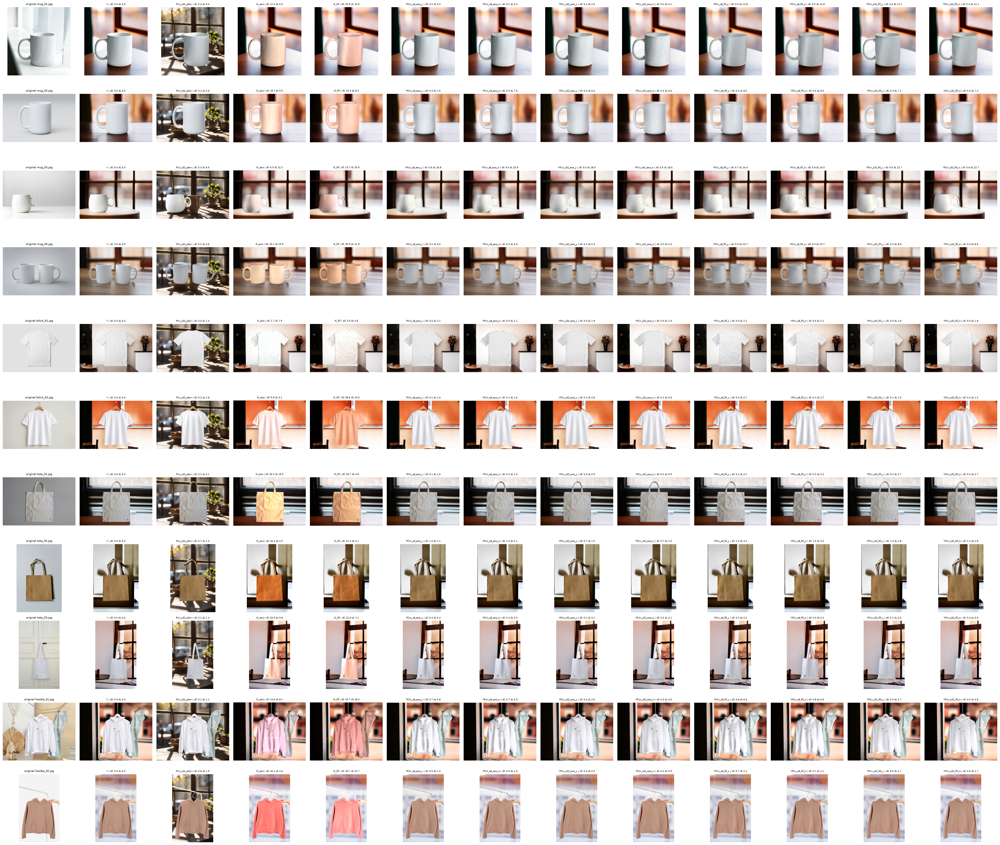

In [6]:
def color_of(m):
    return {'Y': '#54A24B', 'R1n': '#72B7B2', 'IC': '#E45756'}.get(m.split('_')[0], '#4C78A8')


fig, axes = plt.subplots(4, 1, figsize=(14, 15))
x = np.arange(len(ORDER))
for ax, col, title in zip(axes, ['prod_ssim', 'prod_dC', 'prod_dL', 'scene_sim'],
                          ['goods structure kept (SSIM in mask, higher = kept)', 'goods color change (Lab dC in mask, lower = kept)',
                           'goods lighting change (Lab |dL| in mask)', 'scene similarity (CLIP)']):
    ax.bar(x, summ[(col, 'mean')], yerr=summ[(col, 'std')].fillna(0), capsize=2, color=[color_of(m) for m in ORDER])
    ax.set_xticks(x, ORDER, rotation=35, ha='right', fontsize=8)
    ax.set_title(f'{title} (mean ± std)', fontsize=10)
axes[0].set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(OUT_DIR / 'yr_scores.png', dpi=80)
plt.show()

COLS = [m for m in ['Y', 'R1n_s32_plain', 'IC_asis', 'IC_fill'] + [v['method'] for v in VARIANTS] if m in ORDER]
for sc in SCENES:
    names = GOODS.file.tolist()
    fig, axes = plt.subplots(len(names), len(COLS) + 1, figsize=(2.8 * (len(COLS) + 1), 2.8 * len(names)), squeeze=False)
    for i, name in enumerate(names):
        goods, _, _ = inputs(name, sc)
        axes[i, 0].imshow(goods)
        axes[i, 0].set_title(f'original {name}', fontsize=7)
        for j, m in enumerate(COLS):
            r = ds[(ds.goods == name) & (ds.scene == sc) & (ds.method == m)]
            if len(r):
                r = r.iloc[0]
                p = (REL_DIR if m in REF else OUT_DIR / ('ic' if m.startswith('IC_') else '')) / r.file
                axes[i, j + 1].imshow(Image.open(p))
                axes[i, j + 1].set_title(f'{m} | dC {r.prod_dC:.1f} dL {r.prod_dL:.1f}', fontsize=6)
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'yr_grid_{sc}.png', dpi=50)
    plt.show()